In [1]:
%pip install -q langchain-google-genai python-dotenv


Note: you may need to restart the kernel to use updated packages.


In [3]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import os
import operator 


In [4]:
load_dotenv()

True

In [6]:
# Load API key
load_dotenv(override=True)
api_key = os.getenv("Gemini_API_KEY")
if not api_key:
    raise ValueError("Gemini_API_KEY was not found or is empty in .env. Restart the kernel and run this cell again.")

# Initialize Gemini
model = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    google_api_key=api_key,
    temperature=0
)

In [7]:
class EvaluationSchema(BaseModel):
    feedback: str = Field(description='Detailed feedback for the essay ')
    score: int = Field(description='score out of 10', ge=0, le = 10)

In [8]:
Structured_model = model.with_structured_output(EvaluationSchema)

In [9]:
essay = """Artificial Intelligence (AI) is one of the most important technologies of the modern world. It refers to the ability of machines and computers to perform tasks that normally require human intelligence, such as learning, problem-solving, decision-making and understanding languages. India is rapidly developing in the field of AI and using it to improve different sectors of society.

Role of AI in Education

AI is transforming the education system in India. It helps students learn through smart classrooms, online learning platforms and personalised study materials. AI-powered tools can explain difficult topics, solve doubts and help teachers improve the learning experience. It also makes education more accessible to students living in rural areas.

Role of AI in Healthcare

AI plays an important role in improving healthcare services. It helps doctors detect diseases, analyse medical reports and identify health problems at an early stage. AI-based technologies can also support hospitals in managing patient records and providing better medical facilities, especially in areas where doctors are not easily available.

Role of AI in Agriculture

Agriculture is the backbone of the Indian economy. AI helps farmers predict weather conditions, identify crop diseases and monitor soil quality. It can also suggest suitable crops and improve the use of water and fertilisers. This helps farmers increase productivity and reduce losses.

Role of AI in Industries and Economy

AI is helping Indian industries become faster and more efficient. It is used in banking, transportation, manufacturing, business and customer services. It also creates new opportunities for innovation, research and employment. India's growing technology sector can benefit greatly from the development of AI.

Challenges of Artificial Intelligence

Despite its advantages, AI also has some challenges. These include unemployment due to automation, data privacy concerns, cybercrime and the misuse of technology. There is also a need to provide proper AI education and digital facilities to people in rural areas. Therefore, AI must be used carefully and responsibly."""

In [10]:
prompt = f"""Evaluate the language quality of this essay.
Provide detailed feedback and assign a score out of 10.

Essay:
{essay}"""

result = Structured_model.invoke(prompt)

result

EvaluationSchema(feedback='The essay demonstrates a clear, well-structured, and grammatically accurate command of the English language. \n\nStrengths:\n- **Grammar and Mechanics:** The writing is practically free of grammatical errors, spelling mistakes, and punctuation issues. Subject-verb agreement and tense consistency are maintained throughout.\n- **Organization and Clarity:** Ideas are laid out logically using distinct headings and focused paragraphs. The flow from introductory concepts to specific sectoral impacts and concluding challenges is easy to follow.\n- **Tone:** The register is appropriately formal, objective, and informative.\n\nAreas for Improvement:\n- **Sentence Structure Variety:** Many sentences follow a repetitive syntactic pattern (e.g., "AI helps...", "It also...", "It is used in..."). Introducing more varied sentence openings, relative clauses, and compound-complex structures would enhance engagement and readability.\n- **Vocabulary and Lexical Resource:** The 

In [11]:
class UPSCState(TypedDict):
    essay: str
    language_feedback : str 
    analysis_feedback : str
    clarity_feedback : str 
    overall_feedback : str 
    individual_scores : Annotated[list[int], operator.add] # addition operator is used to add three lists
    avg_score : float 

In [12]:
def evaluate_language(state: UPSCState):
    prompt = f'Evaluate the language quality of this essay.Provide detailed feedback and assign a score out of 10.'
    output = Structured_model.invoke(prompt)

    return {'language_feedback' : output.feedback, 'individual_scores' : [output.score]}


In [13]:
def evaluate_analysis(state: UPSCState):
    prompt = f'Evaluate the depth of analysis of this essay.Provide detailed feedback and assign a score out of 10.'
    output = Structured_model.invoke(prompt)

    return {'analysis_feedback' : output.feedback, 'individual_scores' : [output.score]}

In [14]:
def evaluate_thought(state: UPSCState):
    prompt = f'Evaluate the clarity of thought of this essay.Provide detailed feedback and assign a score out of 10.'
    output = Structured_model.invoke(prompt)

    return {'clarity_feedback' : output.feedback, 'individual_scores' : [output.score]}

In [16]:
def final_evaluation(state: UPSCState):
    #summary feedback 
    prompt = f"""Based on the following feedbacks create a summarized feedback
    language feedback {state["language_feedback"]}
    depth of analysis feedback - {state['analysis_feedback']}
    clarity of thought feedback - {state["clarity_feedback"]}"""

    overall_feedback = model.invoke(prompt).content

    #average calculate 
    avg_score = sum(state['individual_scores'])/ len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score':avg_score}

In [17]:
graph = StateGraph(UPSCState)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)


#edges 
graph.add_edge(START, "evaluate_language")
graph.add_edge(START, "evaluate_analysis")
graph.add_edge(START, "evaluate_thought")

graph.add_edge("evaluate_language", 'final_evaluation')
graph.add_edge("evaluate_analysis", 'final_evaluation')
graph.add_edge("evaluate_thought", 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()

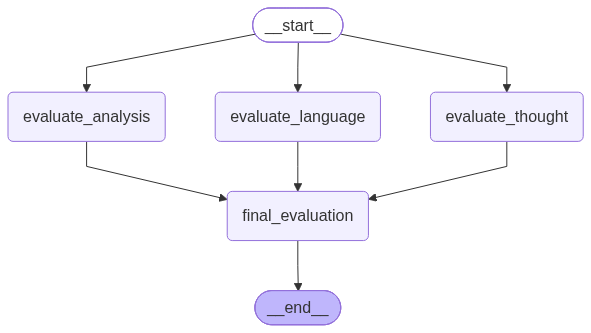

In [18]:
workflow

In [19]:
initial_state = {
    'essay' : essay 
}

workflow.invoke(initial_state)

Retrying langchain_google_genai.chat_models._chat_with_retry.<locals>._chat_with_retry in 2.0 seconds as it raised ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.
Please retry in 12h19m52.371129951s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  description: "Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits."
  quota_metric: "generativelanguage.googleapi

ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.
Please retry in 12h18m48.476160407s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  description: "Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits."
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerDayPerProjectPerModel-FreeTier"
  quota_